# Part 4: Does NLLB-200 translation recover the cross-lingual loss?

Part 3 (BGE-M3, 200 pure-Khmer medical questions vs 2,000 English answers): **EN→EN Hit@1 = 0.90**, **KM→EN direct = 0.65**.

Here we add pipeline 3: **KM → NLLB-200 (distilled-600M) → EN → BGE-M3** against the *same* English answers.

- If it gets close to 0.90 → translation is worth it.
- If it stays near 0.65 → translation doesn't help; the loss comes from the (machine-translated) Khmer questions themselves.

Two translation variants: the whole question at once, and sentence by sentence (NLLB was trained on single sentences; these questions are multi-sentence vignettes).

Separately, NLLB's own quality on **FLORES-200** khm→eng (dev, plus devtest = the standard held-out split): BLEU, spBLEU (flores200 tokenizer, NLLB paper's metric) and chrF++.

In [1]:
# Step 1: Rebuild exactly the part-3 test set (same seed & logic), check it matches out/xling_part3_queries.jsonl
import os
os.environ["USE_TF"] = "0"   # transformers would import TensorFlow (Keras 3) and fail; we only use PyTorch

import re, json, time
import numpy as np
import pandas as pd
import torch

SEED, N_QUERIES, N_CORPUS = 0, 200, 2000
df = pd.read_parquet("data/khmer-medical-qa/data/train-00000-of-00001.parquet")
df = df.drop_duplicates("question_en").reset_index(drop=True)
df["q_km"] = df["question_km"].str.replace(r"^\s*សំណួរ\s*[:：]\s*", "", regex=True).str.strip()
pure = df[~df["q_km"].str.contains(r"[A-Za-z]{2,}", regex=True) & (df["q_km"].str.len() > 20)]
rng = np.random.default_rng(SEED)
q_idx = rng.choice(pure.index.to_numpy(), size=N_QUERIES, replace=False)
d_idx = rng.choice(np.setdiff1d(df.index.to_numpy(), q_idx), size=N_CORPUS - N_QUERIES, replace=False)
corpus_idx = np.concatenate([q_idx, d_idx])
gold = np.arange(N_QUERIES)

saved = pd.read_json("out/xling_part3_queries.jsonl", lines=True)
assert saved["row"].tolist() == q_idx.tolist() and saved["question_km"].tolist() == df.loc[q_idx, "q_km"].tolist()

q_km = saved["question_km"].tolist()
q_en = saved["question_en"].tolist()
corpus_en = df.loc[corpus_idx, "response_en"].tolist()
print(f"OK: same {N_QUERIES} queries as part 3, corpus of {len(corpus_en)} English answers")

OK: same 200 queries as part 3, corpus of 2000 English answers


In [2]:
# Step 2: Load NLLB-200 distilled-600M
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

NLLB_ID = "facebook/nllb-200-distilled-600M"
device = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(NLLB_ID, src_lang="khm_Khmr")
nllb = AutoModelForSeq2SeqLM.from_pretrained(NLLB_ID, torch_dtype=torch.float16 if device == "cuda" else torch.float32).to(device).eval()
ENG = tok.convert_tokens_to_ids("eng_Latn")

@torch.no_grad()
def translate(texts, batch_size=32, num_beams=4, max_new_tokens=400):
    """khm_Khmr -> eng_Latn. Sorted by length for efficient batching; returns in input order."""
    order = np.argsort([-len(t) for t in texts])
    out = [None] * len(texts)
    n_hit_max = 0
    for s in range(0, len(texts), batch_size):
        idx = order[s:s + batch_size]
        enc = tok([texts[i] for i in idx], return_tensors="pt", padding=True, truncation=True, max_length=512).to(device)
        gen = nllb.generate(**enc, forced_bos_token_id=ENG, num_beams=num_beams, max_new_tokens=max_new_tokens)
        n_hit_max += int((gen.shape[1] - 1 >= max_new_tokens) * len(idx))
        for i, t in zip(idx, tok.batch_decode(gen, skip_special_tokens=True)):
            out[i] = t.strip()
    return out, n_hit_max

# sanity check
print(translate(["តើព្យាបាលការខាំពស់យ៉ាងដូចម្តេច?"])[0])

/mnt/mahdipou/miniconda3/envs/senv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


`torch_dtype` is deprecated! Use `dtype` instead!


['How can we treat snake bites?']


In [3]:
# Step 3: Translate the 200 Khmer questions (two variants)
def split_km(text):
    # split after Khmer full stop (។ / ៕) and ? ! ; keep the punctuation with its sentence
    parts = [p.strip() for p in re.split(r"(?<=[។៕?!？])\s*", text) if p.strip()]
    return parts or [text]

t0 = time.time()
tr_whole, hit_w = translate(q_km, max_new_tokens=512)
print(f"whole-question:   {time.time()-t0:.0f}s, {hit_w} outputs hit max length")

sents = [split_km(q) for q in q_km]
flat = [s for ss in sents for s in ss]
t0 = time.time()
flat_tr, hit_s = translate(flat, max_new_tokens=256)
it = iter(flat_tr)
tr_sent = [" ".join(next(it) for _ in ss) for ss in sents]
print(f"sentence-split:   {time.time()-t0:.0f}s, {len(flat)} sentences ({np.mean([len(s) for s in sents]):.1f}/question), {hit_s} hit max length")

pd.DataFrame({"row": saved["row"], "question_km": q_km, "question_en": q_en,
              "nllb_whole": tr_whole, "nllb_sent": tr_sent}).to_json(
    "out/xling_part4_translations.jsonl", orient="records", lines=True, force_ascii=False)

for i in range(3):
    print(f"\n--- example {i}")
    print("original EN :", q_en[i][:250])
    print("NLLB whole  :", tr_whole[i][:250])
    print("NLLB sent   :", tr_sent[i][:250])

whole-question:   6s, 0 outputs hit max length


sentence-split:   6s, 410 sentences (2.0/question), 0 hit max length

--- example 0
original EN : A 42-year-old paraplegic woman with a neurogenic bladder and indwelling urinary catheter develops a urinary tract infection. Imaging studies show a large stone filling and following the contours of the renal pelvis. Based on this presentation, what i
NLLB whole  : A 42-year-old woman with cerebral palsy and kidney failure who had a kidney disease in her body developed an eating disorder. The study showed a large stone head that fills and passes through the blood vessels. Depending on this demonstration, what i
NLLB sent   : A 42-year-old woman with a disability and neurodegenerative diabetes and a kidney failure in her body developed an eating disorder. Visual studies reveal a large stone head that fills and passes through the shape of the blood vessels. Depending on th

--- example 1
original EN : From which specific artery is the tonsillar artery, the principal source of blood supply to 

In [4]:
# Step 4: How close are the translations to the original English questions?
# (the Khmer was machine-translated FROM these, so this is a round-trip measure, not a clean MT score)
import sacrebleu
for name, hyp in [("NLLB whole", tr_whole), ("NLLB sent", tr_sent)]:
    bleu = sacrebleu.corpus_bleu(hyp, [q_en]).score
    chrf = sacrebleu.corpus_chrf(hyp, [q_en], word_order=2).score
    print(f"{name:<11} vs original English question:  BLEU {bleu:5.1f}   chrF++ {chrf:5.1f}")

NLLB whole  vs original English question:  BLEU  25.0   chrF++  46.5
NLLB sent   vs original English question:  BLEU  25.8   chrF++  48.1


In [5]:
# Step 5: Retrieval with BGE-M3 — compare the pipelines on the same 2,000 English answers
del nllb; torch.cuda.empty_cache()
from sentence_transformers import SentenceTransformer
bge = SentenceTransformer("BAAI/bge-m3", device=device)
enc = lambda texts: bge.encode(texts, batch_size=64, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)

d_emb = enc(corpus_en)
PIPELINES = {
    "1. EN→EN (baseline)":        q_en,
    "2. KM→EN direct":            q_km,
    "3a. KM→NLLB(whole)→EN":      tr_whole,
    "3b. KM→NLLB(sentences)→EN":  tr_sent,
}
rows, ranks = [], {}
for name, qs in PIPELINES.items():
    sim = enc(qs) @ d_emb.T
    r = (sim > sim[np.arange(N_QUERIES), gold][:, None]).sum(1) + 1
    ranks[name] = r
    rows.append({"pipeline": name, "Hit@1": np.mean(r == 1), "Hit@5": np.mean(r <= 5),
                 "MRR@10": np.mean(np.where(r <= 10, 1 / r, 0))})
res = pd.DataFrame(rows).set_index("pipeline")
base, direct = res.loc["1. EN→EN (baseline)", "Hit@1"], res.loc["2. KM→EN direct", "Hit@1"]
res["gap recovered (Hit@1)"] = (res["Hit@1"] - direct) / (base - direct)
res.to_csv("out/xling_part4_retrieval.csv")
print(res.to_string(float_format=lambda x: f"{x:.3f}", formatters={"gap recovered (Hit@1)": lambda x: f"{x:+.0%}"}))

                           Hit@1  Hit@5  MRR@10 gap recovered (Hit@1)
pipeline                                                             
1. EN→EN (baseline)        0.895  0.970   0.928                 +100%
2. KM→EN direct            0.650  0.790   0.709                   +0%
3a. KM→NLLB(whole)→EN      0.695  0.820   0.747                  +18%
3b. KM→NLLB(sentences)→EN  0.695  0.860   0.758                  +18%


In [6]:
# Step 6: Where do queries win/lose? (Hit@1, per query)
best3 = max(["3a. KM→NLLB(whole)→EN", "3b. KM→NLLB(sentences)→EN"], key=lambda k: res.loc[k, "Hit@1"])
en_ok, dir_ok, tr_ok = ranks["1. EN→EN (baseline)"] == 1, ranks["2. KM→EN direct"] == 1, ranks[best3] == 1
print(f"Using {best3}")
print(f"  EN fails too (question itself hard)       : {(~en_ok).sum():3d}")
print(f"  EN ok, direct ok,   translated ok          : {(en_ok & dir_ok & tr_ok).sum():3d}")
print(f"  EN ok, direct FAIL, translated ok (gained) : {(en_ok & ~dir_ok & tr_ok).sum():3d}")
print(f"  EN ok, direct ok,   translated FAIL (lost) : {(en_ok & dir_ok & ~tr_ok).sum():3d}")
print(f"  EN ok, both FAIL (lost in Khmer itself)    : {(en_ok & ~dir_ok & ~tr_ok).sum():3d}")

tr_used = tr_whole if best3.startswith("3a") else tr_sent
for i in np.where(en_ok & ~tr_ok)[0][:3]:
    print(f"\n--- query {i}: EN rank 1, translated rank {ranks[best3][i]}")
    print("original EN:", q_en[i][:220])
    print("NLLB       :", tr_used[i][:220])

Using 3a. KM→NLLB(whole)→EN
  EN fails too (question itself hard)       :  21
  EN ok, direct ok,   translated ok          : 116
  EN ok, direct FAIL, translated ok (gained) :  21
  EN ok, direct ok,   translated FAIL (lost) :  12
  EN ok, both FAIL (lost in Khmer itself)    :  30

--- query 0: EN rank 1, translated rank 27
original EN: A 42-year-old paraplegic woman with a neurogenic bladder and indwelling urinary catheter develops a urinary tract infection. Imaging studies show a large stone filling and following the contours of the renal pelvis. Base
NLLB       : A 42-year-old woman with cerebral palsy and kidney failure who had a kidney disease in her body developed an eating disorder. The study showed a large stone head that fills and passes through the blood vessels. Depending

--- query 5: EN rank 1, translated rank 8
original EN: A 22-year-old woman experiences severe pruritus on her left leg after a hiking trip where something brushed her skin. She presents with red, pruritic 

In [7]:
# Step 7: NLLB quality on FLORES-200 khm→eng (independent of our medical data)
del bge; torch.cuda.empty_cache()
nllb = AutoModelForSeq2SeqLM.from_pretrained(NLLB_ID, torch_dtype=torch.float16 if device == "cuda" else torch.float32).to(device).eval()

FL = "data/flores200/flores200_dataset"
flores_rows = []
for split in ["dev", "devtest"]:
    src = open(f"{FL}/{split}/khm_Khmr.{split}", encoding="utf-8").read().splitlines()
    ref = open(f"{FL}/{split}/eng_Latn.{split}", encoding="utf-8").read().splitlines()
    t0 = time.time()
    hyp, nmax = translate(src, batch_size=64, max_new_tokens=256)
    open(f"out/flores_khm-eng_{split}.nllb600m.txt", "w", encoding="utf-8").write("\n".join(hyp) + "\n")
    row = {"split": split, "n": len(src),
           "BLEU": sacrebleu.corpus_bleu(hyp, [ref]).score,
           "chrF++": sacrebleu.corpus_chrf(hyp, [ref], word_order=2).score}
    try:
        row["spBLEU(flores200)"] = sacrebleu.corpus_bleu(hyp, [ref], tokenize="flores200").score
    except Exception as e:
        print("spBLEU unavailable:", type(e).__name__, e)
    flores_rows.append(row)
    print(f"{split}: {len(src)} sentences in {time.time()-t0:.0f}s, {nmax} hit max length")

flores = pd.DataFrame(flores_rows).set_index("split")
flores.to_csv("out/flores_khm-eng_nllb600m_scores.csv")
print(flores.to_string(float_format=lambda x: f"{x:.1f}"))
print("\nexample:\n SRC:", src[0][:150], "\n REF:", ref[0][:150], "\n HYP:", hyp[0][:150])

dev: 997 sentences in 17s, 0 hit max length


devtest: 1012 sentences in 12s, 0 hit max length
            n  BLEU  chrF++  spBLEU(flores200)
split                                         
dev       997  30.9    54.9               33.2
devtest  1012  28.6    53.1               31.3

example:
 SRC: "គាត់​បាន​បន្ថែម​ថា បច្ចុប្បន្ន​នេះ យើង​មាន​កណ្ដុរ​ដែល​មាន​អាយុ 4 ខែ ដែល​គ្មាន​ជំងឺ​ទឹក​នោ​ម​ផ្អែម ដែល​ពីមុន​វា​ធ្លាប់​មាន​ជំងឺ​ទឹកនោមផ្អែម។ " 
 REF: "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added. 
 HYP: "We now have a four-month-old mosquito without diabetes", he added.


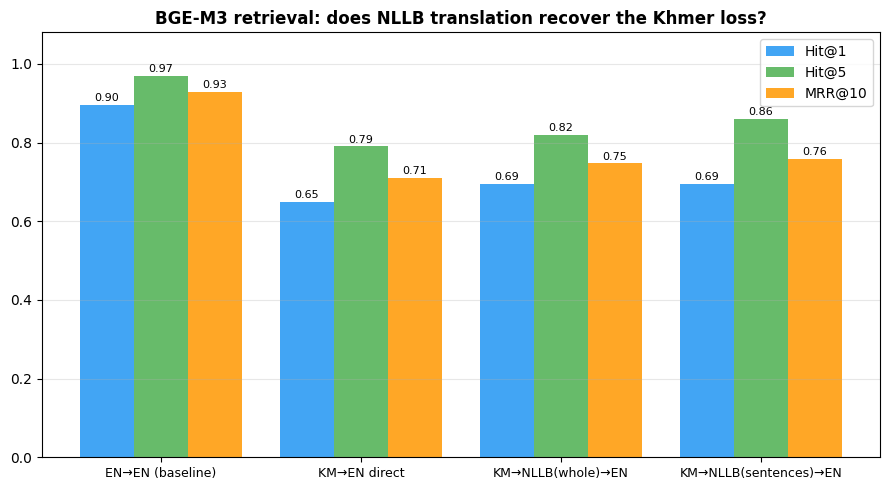

In [8]:
# Step 8: Plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 5))
names = list(PIPELINES)
x, w = np.arange(len(names)), 0.27
for i, (m, c) in enumerate([("Hit@1", "#2196F3"), ("Hit@5", "#4CAF50"), ("MRR@10", "#FF9800")]):
    bars = ax.bar(x + (i - 1) * w, res[m].values, w, label=m, color=c, alpha=0.85)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([n.split(". ", 1)[1] for n in names], fontsize=9)
ax.set_ylim(0, 1.08); ax.grid(axis="y", alpha=0.3); ax.legend()
ax.set_title("BGE-M3 retrieval: does NLLB translation recover the Khmer loss?", fontweight="bold")
plt.tight_layout(); plt.savefig("out/xling_part4.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()